In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


df = pd.read_excel('dados/economi.xlsx')

df['P - nivel de precos'] = (df['M - oferta monetaria'] * df['V - velocidade'] ) / df['Y - produto real']


df['Taxa de crescimento - M'] = df['M - oferta monetaria'].pct_change() * 100
df['Taxa de crescimento - V'] = df['V - velocidade'].pct_change() * 100
df['Taxa de crescimento - Y'] = df['Y - produto real'].pct_change() * 100
df['Taxa de crescimento - P'] = df['P - nivel de precos'].pct_change() * 100

df.head()


,Trimestre,Ano,M - oferta monetaria,V - velocidade,Y - produto real,P - nivel de precos,Taxa de crescimento - M,Taxa de crescimento - V,Taxa de crescimento - Y,Taxa de crescimento - P
0,2020T1,2020,103.665,0.98913,101.453,1.010696,NaN,NaN,NaN,NaN
1,2020T2,2020,107.297,0.97758,100.382,1.044922,3.503593,-1.167693,-1.055661,3.386399
2,2020T3,2020,111.334,0.95334,100.716,1.053846,3.762454,-2.479592,0.332729,0.853997
3,2020T4,2020,115.307,0.94183,101.323,1.071816,3.568542,-1.207334,0.602685,1.705162
4,2021T1,2021,117.442,0.94028,102.656,1.075713,1.851579,-0.164573,1.315595,0.363580


C:\Users\igorp\AppData\Local\Temp\ipykernel_18160\1512047699.py:69: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[1, 0].legend()


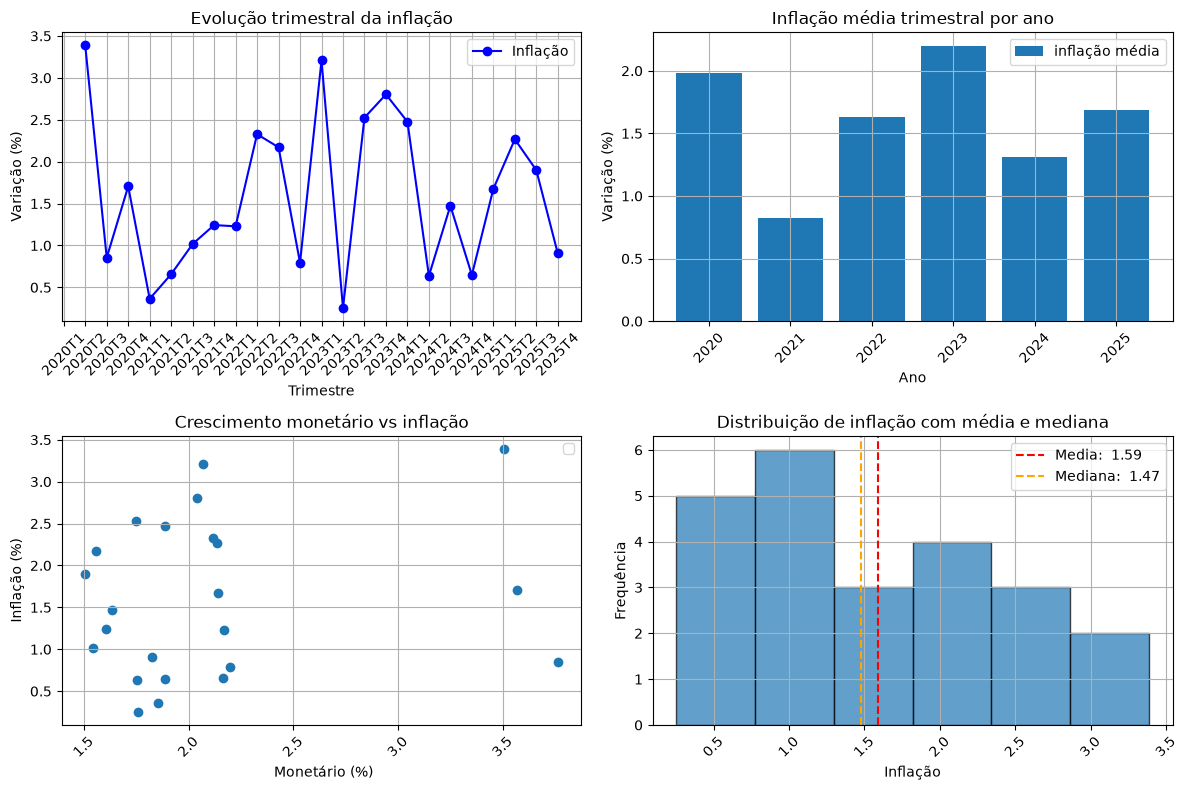

Média(%)                1.587785
Mediana (%)             1.474459
Desvio padrão (p.p.)    0.920075
Maior inflação (%)      3.386399
Menor inflação (%)      0.253186
dtype: float64

In [12]:
fig, axs = plt.subplots(2,2, figsize=(12,8))

axs[0, 0].plot(
    df['Trimestre'],
    df['Taxa de crescimento - P'],
    label='Inflação',
    color='blue',
    marker='o'
)

inflacao_media = df.groupby('Ano')['Taxa de crescimento - P'].mean()

axs[0, 1].bar(
    inflacao_media.index,
    inflacao_media,
    label='inflação média'
)

axs[1, 0].scatter(
    df['Taxa de crescimento - M'],
    df['Taxa de crescimento - P']
)

inflacao = df['Taxa de crescimento - P'].dropna()

media = inflacao.mean()
mediana = inflacao.median()

axs[1, 1].hist(
    inflacao,
    bins=6,
    edgecolor='black',
    alpha=0.7
)

axs[1, 1].axvline(
    media,
    color='red',
    linestyle='--',
    label= f'Media: {media: .2f}'
    
)

axs[1, 1].axvline(
    mediana,
    color='orange',
    linestyle='--',
    label= f'Mediana: {mediana: .2f}'
    
)

axs[0, 0].set_title('Evolução trimestral da inflação')
axs[0, 0].set_xlabel('Trimestre')
axs[0, 0].set_ylabel('Variação (%)')

axs[0, 0].legend()


axs[0, 1].set_title('Inflação média trimestral por ano')
axs[0, 1].set_xlabel('Ano')
axs[0, 1].set_ylabel('Variação (%)')

axs[0, 1].legend()

axs[1, 0].set_title('Crescimento monetário vs inflação')
axs[1, 0].set_xlabel(' Monetário (%)')
axs[1, 0].set_ylabel('Inflação (%)')

axs[1, 0].legend()

axs[1, 1].set_title('Distribuição de inflação com média e mediana')
axs[1, 1].set_xlabel('Inflação')
axs[1, 1].set_ylabel('Frequência')

axs[1, 1].legend()


for ax in axs.flatten():
    ax.grid(True)
    ax.tick_params(axis='x', rotation=45)

    
plt.tight_layout()

plt.show()

#resumo


desvio_padrao = inflacao.std()
maior_inflacao = inflacao.max()
menor_inflacao = inflacao.min()


df_resumo = pd.Series({
    'Média(%)': media,
    'Mediana (%)': mediana,
    'Desvio padrão (p.p.)': desvio_padrao,
    'Maior inflação (%)': maior_inflacao,
    'Menor inflação (%)': menor_inflacao
})


display(df_resumo)

